# Deaths per reported case across COVID-19 waves
This is an exploratory ratio analysis, **not** a case-fatality-risk estimate. Deaths often occur weeks after diagnosis, reporting is incomplete, and the case denominator changed over time. We compare raw weekly ratios, smoothed ratios, and simple lagged correlation.

In [ ]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt

ROOT=Path.cwd()
if not (ROOT/"data/processed/us_covid_clean.csv").exists(): ROOT=ROOT.parent
df=pd.read_csv(ROOT/"data/processed/us_covid_clean.csv",parse_dates=["week_ending"]).sort_values("week_ending")
waves=pd.read_csv(ROOT/"data/processed/us_covid_waves.csv",parse_dates=["start_date","end_date"])
df["death_case_ratio"]=df.new_deaths/df.new_cases.replace(0,np.nan)
df["ratio_4wk"]=df.death_case_ratio.rolling(4,min_periods=2).mean()
df.head()

,week_ending,total_cases,total_deaths,new_cases,new_deaths,week,cases_reported,death_case_ratio,ratio_4wk
0,2020-01-26,7,0,7.0,0.0,0,True,0.0,NaN
1,2020-02-02,9,0,2.0,0.0,1,True,0.0,0.0
2,2020-02-09,20,0,11.0,0.0,2,True,0.0,0.0
3,2020-02-16,24,0,4.0,0.0,3,True,0.0,0.0
4,2020-02-23,40,0,16.0,0.0,4,True,0.0,0.0


## 1. Weekly deaths and cases, with smoothed ratio

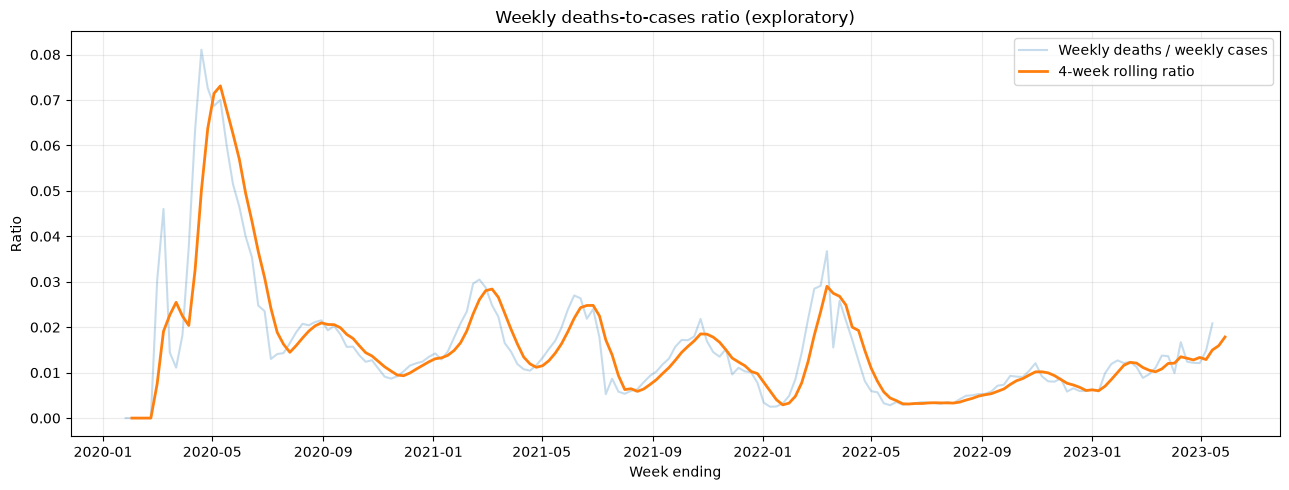

In [2]:
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(df.week_ending,df.death_case_ratio,alpha=.25,label="Weekly deaths / weekly cases")
ax.plot(df.week_ending,df.ratio_4wk,linewidth=2,label="4-week rolling ratio")
ax.set(title="Weekly deaths-to-cases ratio (exploratory)",xlabel="Week ending",ylabel="Ratio")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout()

## 2. Wave-level descriptive summary
Wave boundaries are taken from the supplied wave summary. For each wave, we report total reported deaths divided by total reported cases, which is less volatile than averaging weekly ratios. It still is not a cohort-based fatality risk because deaths and cases are not linked by infection date.

In [3]:
rows=[]
wave_dir=ROOT/"data/processed/waves"
for _,w in waves.iterrows():
    wave_path=wave_dir/f"us_covid_wave_{int(w.wave)}.csv"
    if wave_path.exists():
        sub=pd.read_csv(wave_path,parse_dates=["week_ending"])
    else:
        # Fallback to the summary's dates if wave-specific CSVs are absent.
        sub=df[(df.week_ending>=w.start_date)&(df.week_ending<=w.end_date)]
    cases=sub.new_cases.sum(); deaths=sub.new_deaths.sum()
    rows.append({"wave":int(w.wave),"start":sub.week_ending.min().date(),"end":sub.week_ending.max().date(),"cases_sum":cases,"deaths_sum":deaths,"death_to_case_ratio":deaths/cases if cases else np.nan})
wave_ratio=pd.DataFrame(rows)
wave_ratio


,wave,start,end,cases_sum,deaths_sum,death_to_case_ratio
0,1,2020-01-26,2020-09-13,6515345.0,198641.0,0.030488
1,2,2020-09-20,2021-06-27,26756518.0,401680.0,0.015012
2,3,2021-07-04,2021-11-07,12878033.0,151815.0,0.011789
3,4,2021-11-14,2022-04-03,33347746.0,225718.0,0.006769
4,5,2022-04-10,2022-10-30,16677650.0,82065.0,0.004921
5,6,2022-11-06,2024-08-04,7261537.0,133246.0,0.018350


## 3. Lag sensitivity
We calculate Pearson correlation between weekly cases and deaths shifted by 0–8 weeks. This helps demonstrate temporal displacement, but correlation is not a causal estimate and the aggregate waves are influenced by reporting artifacts.

,death_lag_weeks,correlation
0,0,0.606715
1,1,0.658542
2,2,0.686931
3,3,0.684412
4,4,0.650303
5,5,0.589274
6,6,0.509228
7,7,0.422046
8,8,0.337736


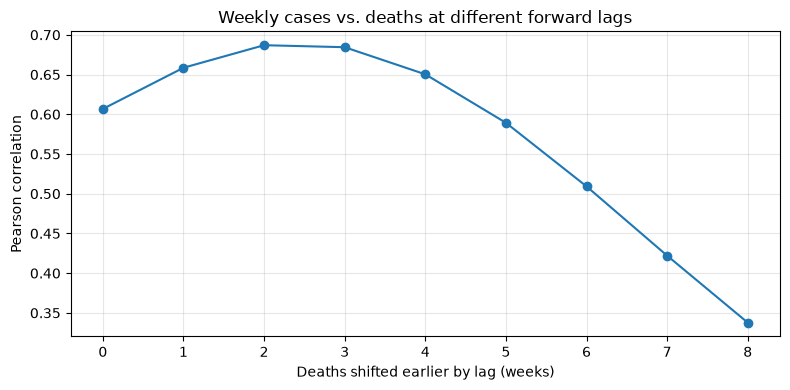

In [4]:
lag_results=[]
for lag in range(9):
    aligned=pd.concat([df.new_cases,df.new_deaths.shift(-lag)],axis=1).dropna()
    corr=aligned.iloc[:,0].corr(aligned.iloc[:,1]) if len(aligned)>2 else np.nan
    lag_results.append({"death_lag_weeks":lag,"correlation":corr})
lag_df=pd.DataFrame(lag_results)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(lag_df.death_lag_weeks,lag_df.correlation,"o-")
ax.set(title="Weekly cases vs. deaths at different forward lags",xlabel="Deaths shifted earlier by lag (weeks)",ylabel="Pearson correlation")
ax.grid(alpha=.3); plt.tight_layout()
lag_df

In [5]:
outdir=ROOT/"results"; outdir.mkdir(exist_ok=True)
wave_ratio.to_csv(outdir/"deaths_per_case_by_wave.csv",index=False)
lag_df.to_csv(outdir/"cases_deaths_lag_correlation.csv",index=False)
print("Exported wave ratios and lag-correlation tables to",outdir)

Exported wave ratios and lag-correlation tables to c:\Users\tchin\Downloads\COVID19-Logistic-Growth-Project\results
